In [5]:
#Hook Colab up to Drive
import sys
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')
sys.path.append(str(DATA_DIR))
FIG_DIR = DATA_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
LOG = DATA_DIR / 'results_log.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
#Each model's best setting, picked by validation F1 from the sweeps
BEST = {
    'LR':  {'C': 1.0},
    'RF':  {'n_estimators': 100, 'max_depth': None},
    'MLP': {'hidden': (128, 64, 32), 'dropout': 0.0},
    'CNN': {'embed_dim': 64},
}

Running on cuda
              Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Logistic Regression  test    0.9998        1.0  0.9996 0.9998   0.9999     1.0                0                6


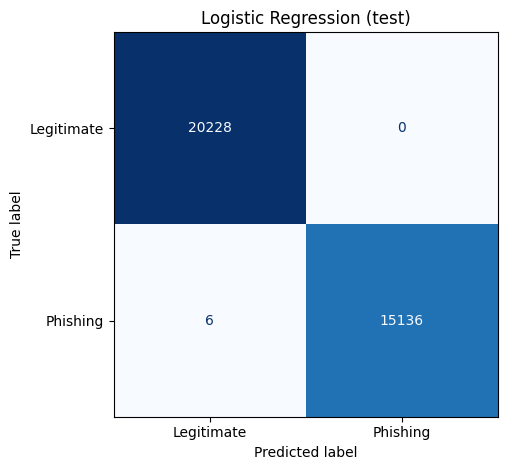

        Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Random Forest  test    0.9999        1.0  0.9999 0.9999      1.0     1.0                0                2


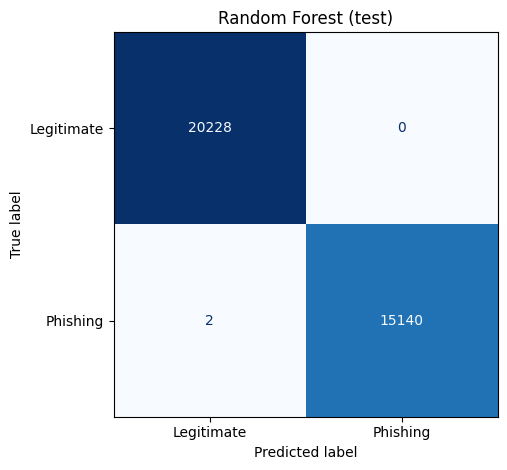

/content/drive/MyDrive/DeepMinds/project_utils.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  new = pd.concat([pd.read_csv(log_file), new], ignore_index=True)


Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
  MLP  test    0.9999     0.9999  0.9999 0.9999   0.9999     1.0                1                2


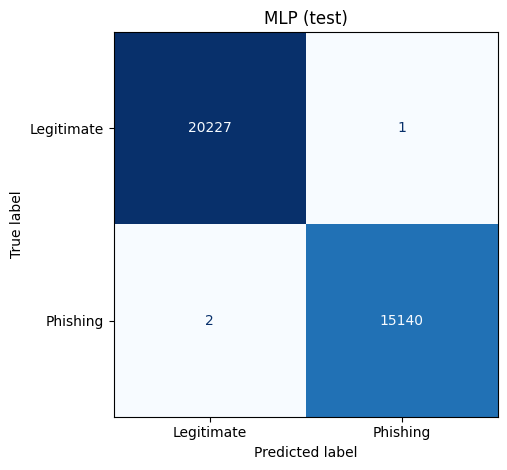

   Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Char-CNN  test    0.9984        1.0  0.9962 0.9981   0.9991  0.9992                0               58


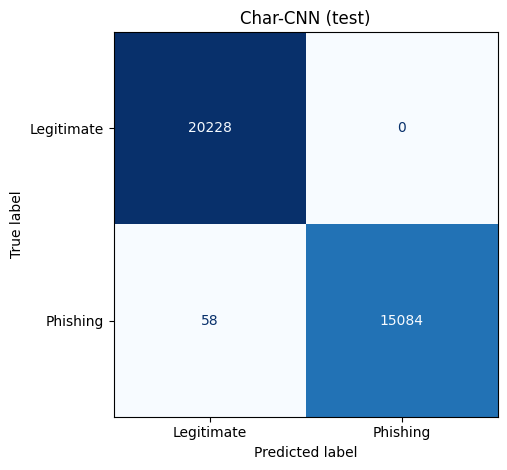

In [8]:
#Retraining each model with its best setting and score it on the TEST set
import torch
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from project_utils import URL_FEATURES, load_master, get_feature_splits, evaluate_model, log_result
from torch_models import fit_mlp, fit_char_cnn, predict_proba, DEVICE

print('Running on', DEVICE)
df = load_master(DATA_DIR)
data, _ = get_feature_splits(df, URL_FEATURES)
(Xtr, ytr), (Xte, yte) = data['train'], data['test']
probs, rows = {}, []

lr = LogisticRegression(**BEST['LR'], max_iter=1000, random_state=42).fit(Xtr, ytr)
probs['Logistic Regression'] = lr.predict_proba(Xte)[:, 1]

rf = RandomForestClassifier(**BEST['RF'], random_state=42, n_jobs=-1).fit(Xtr, ytr)
probs['Random Forest'] = rf.predict_proba(Xte)[:, 1]

mlp, _, mlp_cfg = fit_mlp(data, BEST['MLP'], verbose=False)
probs['MLP'] = predict_proba(mlp, Xte)

cnn, _, cnn_cfg, seqs, _ = fit_char_cnn(df, BEST['CNN'], verbose=False)
X_seq_te, y_seq_te = seqs['test']
assert (y_seq_te == yte).all()
probs['Char-CNN'] = predict_proba(cnn, X_seq_te, x_dtype=torch.long)

hp = {'Logistic Regression': ('LR', BEST['LR']), 'Random Forest': ('RF', BEST['RF']),
      'MLP': ('MLP', mlp_cfg), 'Char-CNN': ('CNN', cnn_cfg)}

for name, p in probs.items():
    res = evaluate_model(name, 'test', yte, p, save_path=FIG_DIR / f'cm_test_{hp[name][0].lower()}.png')
    log_result(res, {'family': hp[name][0], 'experiment': 'final', **hp[name][1]}, LOG)
    rows.append(res)

In [9]:
#Saving the final results table and predictions for Liliana's report figures
final = pd.DataFrame(rows)
final.to_csv(DATA_DIR / 'final_test_results.csv', index=False)
pd.DataFrame({'label': yte, **probs}).to_csv(DATA_DIR / 'final_test_predictions.csv', index=False)
print(final.round(4).to_string(index=False))

              Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Logistic Regression  test    0.9998     1.0000  0.9996 0.9998   0.9999  1.0000                0                6
      Random Forest  test    0.9999     1.0000  0.9999 0.9999   1.0000  1.0000                0                2
                MLP  test    0.9999     0.9999  0.9999 0.9999   0.9999  1.0000                1                2
           Char-CNN  test    0.9984     1.0000  0.9962 0.9981   0.9991  0.9992                0               58


Final test is done and saved in final_test_results.csv. RF and MLP missed 2, LR missed 6, CNN missed 58.